In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch, FontManager, Sbopen
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

In [11]:
data = pd.read_csv("Sample_Game_2_RawEventsData.csv")

In [12]:
data = data[data["Type"] == 'PASS']
data

,Team,Type,Subtype,Period,Start Frame,Start Time [s],End Frame,End Time [s],From,To,Start X,Start Y,End X,End Y
1,Away,PASS,NaN,1,51,2.04,87,3.48,Player23,Player20,0.50,0.50,0.40,0.51
2,Away,PASS,NaN,1,146,5.84,186,7.44,Player20,Player18,0.43,0.50,0.44,0.22
3,Away,PASS,NaN,1,248,9.92,283,11.32,Player18,Player17,0.47,0.19,0.31,0.28
4,Away,PASS,NaN,1,316,12.64,346,13.84,Player17,Player16,0.29,0.32,0.26,0.58
5,Away,PASS,NaN,1,395,15.80,423,16.92,Player16,Player15,0.26,0.66,0.27,0.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1914,Home,PASS,NaN,2,137209,5488.36,137221,5488.84,Player1,Player6,0.41,0.32,0.46,0.43
1915,Home,PASS,NaN,2,137263,5490.52,137303,5492.12,Player6,Player1,0.46,0.32,0.38,0.18
1916,Home,PASS,NaN,2,137303,5492.12,137332,5493.28,Player1,Player5,0.38,0.18,0.49,0.11
1917,Home,PASS,NaN,2,137334,5493.36,137359,5494.36,Player5,Player1,0.49,0.11,0.35,0.11


In [13]:
data["Start X"] = data["Start X"]*120
data["Start X"]

1        60.0
2        51.6
3        56.4
4        34.8
5        31.2
        ...  
1914     49.2
1915     55.2
1916     45.6
1917     58.8
1929    104.4
Name: Start X, Length: 964, dtype: float64

In [14]:
data["Start Y"] = data["Start Y"]*80
data["Start Y"]

1       40.0
2       40.0
3       15.2
4       25.6
5       52.8
        ... 
1914    25.6
1915    25.6
1916    14.4
1917     8.8
1929    40.0
Name: Start Y, Length: 964, dtype: float64

In [15]:
data["End X"] = data["End X"]*120
data["End X"]

1       48.0
2       52.8
3       37.2
4       31.2
5       32.4
        ... 
1914    55.2
1915    45.6
1916    58.8
1917    42.0
1929    76.8
Name: End X, Length: 964, dtype: float64

In [16]:
data["End Y"] = data["End Y"]*80
data["End Y"]

1       40.8
2       17.6
3       22.4
4       46.4
5       72.8
        ... 
1914    34.4
1915    14.4
1916     8.8
1917     8.8
1929    64.0
Name: End Y, Length: 964, dtype: float64

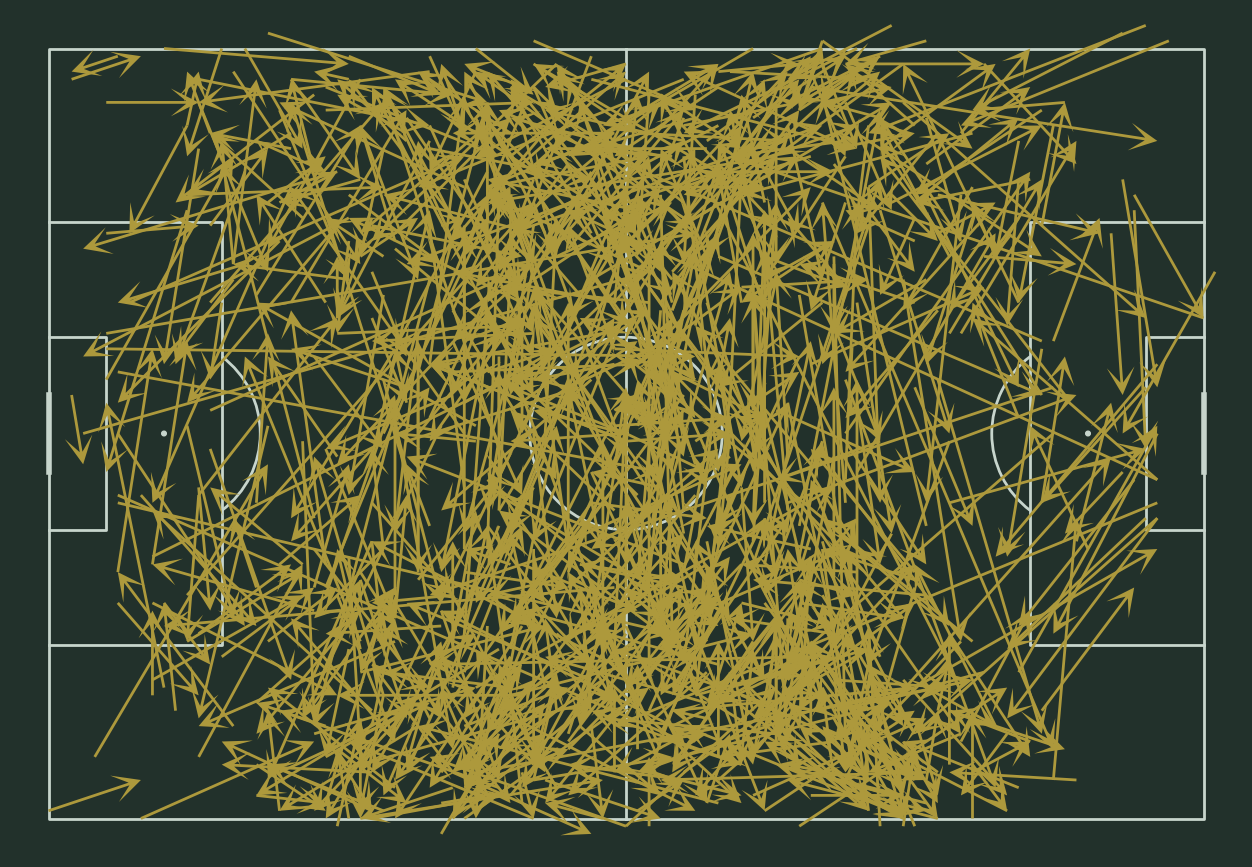

In [17]:
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('#22312b')

pitch.arrows(data["Start X"], data["Start Y"],
             data["End X"], data["End Y"], width=2,
             headwidth=10, headlength=10, color='#ad993c', ax=ax, label='completed passes')

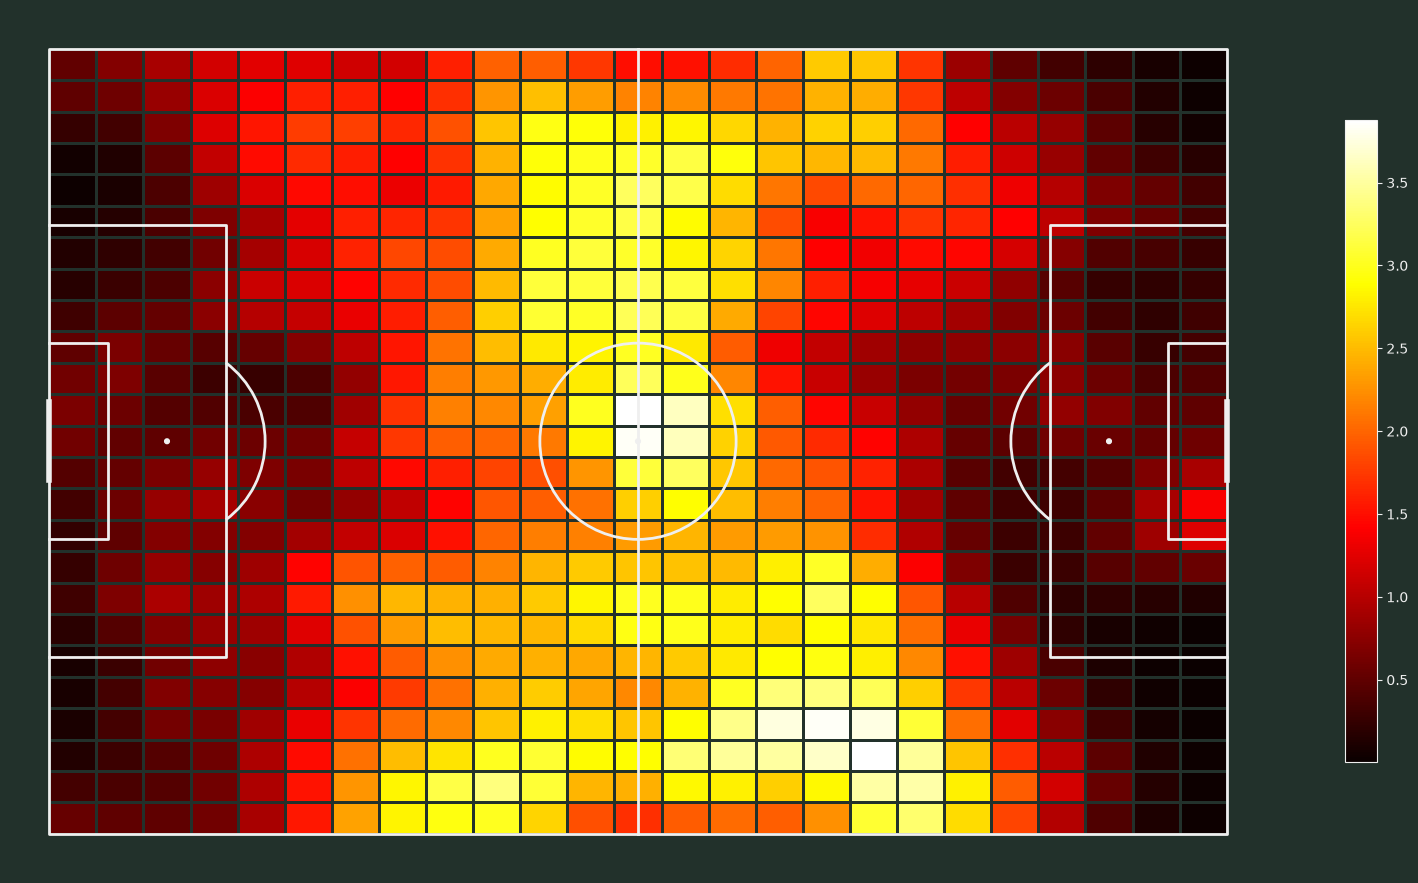

In [ ]:
pitch = Pitch(pitch_type='statsbomb', line_zorder=2,
              pitch_color='#22312b', line_color='#efefef')
fig, ax = pitch.draw(figsize=(16,11))
fig.set_facecolor('#22312b')
bin_statistic = pitch.bin_statistic(data["Start X"], data["Start Y"], statistic='count', bins=(25, 25))
bin_statistic['statistic'] = gaussian_filter(bin_statistic['statistic'], 1)
pcm = pitch.heatmap(bin_statistic, ax=ax, cmap='hot', edgecolors='#22312b')
cbar = fig.colorbar(pcm, ax=ax, shrink=0.6)
cbar.outline.set_edgecolor('#efefef')
cbar.ax.yaxis.set_tick_params(color='#efefef')
ticks = plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='#efefef')